# Лабораторная работа № 3. Стационарность и корреляционный анализ

**Выполнил: Голубенко Никита**

**Цель.** Проверить стационарность синтетического временного ряда, построить ACF и PACF, выполнить тесты ADF, PP, KPSS и DF-GLS, подобрать обычное и сезонное дифференцирование и сравнить ручной выбор с `pmdarima`.

В ноутбуке используется воспроизводимый почасовой синтетический ряд с линейным трендом, суточной и недельной сезонностями, структурным сдвигом и 12 искусственно добавленными выбросами.

## Теоретическая основа

**Строгая стационарность** означает, что совместное распределение любых конечных наборов наблюдений не меняется при одинаковом сдвиге времени. **Слабая стационарность** требует постоянного математического ожидания и конечной постоянной дисперсии, а автоковариация должна зависеть только от лага. Для классических моделей ARMA обычно достаточно слабой стационарности. Строгая стационарность при конечном втором моменте влечёт слабую, но обратное в общем случае неверно.

**Эргодичность** позволяет оценивать теоретические характеристики процесса по одной достаточно длинной реализации: временные средние должны сходиться к соответствующим ансамблевым характеристикам. Одной стационарности для такого перехода недостаточно.

ACF показывает общую корреляцию с прошлыми значениями, PACF — связь с лагом после учёта промежуточных лагов. CCF характеризует взаимосвязь **двух разных** временных рядов. В этой работе анализируется один ряд, поэтому CCF не строится. Для неё потребовался бы второй сопоставимый ряд, например внешний показатель трафика или температуры.

## 1. Импорт библиотек

Для ACF/PACF и критерия Ljung–Box используются `statsmodels`, для автоматического выбора порядков `d` и `D` — `pmdarima`, для ADF, PP, KPSS и DF-GLS — `arch.unitroot`. Все четыре теста в одном запуске рассчитываются одной реализацией.

In [1]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
from IPython.display import display, Markdown
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.tsa.stattools import acf
from statsmodels.stats.diagnostic import acorr_ljungbox
from pmdarima.arima import ndiffs, nsdiffs

try:
    import arch as arch_package
    from arch.unitroot import ADF, PhillipsPerron, KPSS, DFGLS
    ARCH_AVAILABLE = True
    ARCH_VERSION = arch_package.__version__
except ImportError:
    ARCH_AVAILABLE = False
    ARCH_VERSION = "не установлен"

SEED = 42
rng = np.random.default_rng(SEED)
plt.rcParams["figure.figsize"] = (14, 5)

# Все таблицы и рисунки сохраняются в отдельную папку относительно рабочей директории.
OUTPUT_DIR = Path.cwd() / "results_lecture3_stationarity"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

def save_figure(fig, filename):
    """Сохраняет рисунок в OUTPUT_DIR с достаточным разрешением."""
    path = OUTPUT_DIR / filename
    fig.savefig(path, dpi=160, bbox_inches="tight")
    print("График сохранён:", path)

print("Библиотеки импортированы. Seed =", SEED)
print("Пакет arch доступен:", ARCH_AVAILABLE, "| версия:", ARCH_VERSION)
print("pmdarima:", __import__("pmdarima").__version__)

pd.set_option("display.max_colwidth", None)
pd.set_option("display.width", 2000)
pd.set_option("display.max_columns", None)
pd.set_option("display.expand_frame_repr", False)

def format_pvalue(value):
    """Форматирует p-value без отображения нулевого значения."""
    if pd.isna(value):
        return "нет результата"
    value = float(value)
    if value == 0.0:
        return "< 0,000001"
    return f"{value:.6g}".replace(".", ",")

def format_test_table(table):
    """Готовит статистики и p-value для компактного отображения."""
    result = table.copy()
    if "Статистика" in result.columns:
        result["Статистика"] = result["Статистика"].map(
            lambda x: "—" if pd.isna(x) else f"{float(x):.6f}".replace(".", ",")
        )
    if "p-value" in result.columns:
        result["p-value"] = result["p-value"].map(format_pvalue)
    return result

def display_full_table(table):
    """Выводит таблицу целиком с переносом длинных значений."""
    styled = (
        table.style
        .set_properties(**{
            "white-space": "normal",
            "overflow-wrap": "anywhere",
            "word-break": "normal",
            "text-align": "left",
            "vertical-align": "top"
        })
        .set_table_styles([
            {"selector": "th", "props": [("white-space", "normal"), ("vertical-align", "top"), ("text-align", "center")]},
            {"selector": "td", "props": [("max-width", "520px"), ("white-space", "normal"), ("overflow-wrap", "anywhere")]},
            {"selector": "table", "props": [("width", "100%"), ("table-layout", "auto")]},
        ])
    )
    display(styled)

Библиотеки импортированы. Seed = 42
Пакет arch доступен: True | версия: 8.0.0
pmdarima: 2.1.1


## 2. Генерация ряда

Используется 17 544 почасовых наблюдения с 1 января 2023 года по 31 декабря 2024 года. Суточный период равен 24 часам, недельный — 168 часам. В ряд включены линейный тренд, скачок уровня с 1 марта 2024 года и 12 точечных выбросов. Генератор детерминирован благодаря фиксированному `Seed = 42`. Даты и величины искусственных выбросов сохраняются отдельно, чтобы проверить чувствительность тестов к ним.

In [2]:
N = 24 * 365 * 2 + 24
index = pd.date_range("2023-01-01", periods=N, freq="h")
t = np.arange(N, dtype=float)
DAILY_PERIOD, WEEKLY_PERIOD = 24, 168
SHIFT_START = pd.Timestamp("2024-03-01")
LEVEL_SHIFT = 18.0

trend = 0.0035 * t
daily = 28 * np.sin(2 * np.pi * t / 24) + 8 * np.cos(2 * np.pi * t / 24)
weekly = 16 * np.sin(2 * np.pi * t / 168 + 0.6)
noise = rng.normal(0, 9, N)
shift = np.where(index >= SHIFT_START, LEVEL_SHIFT, 0.0)
y = 150 + trend + daily + weekly + shift + noise

outlier_indices = np.linspace(300, N - 500, 12, dtype=int)
outlier_effects = rng.choice([-1, 1], len(outlier_indices)) * rng.uniform(100, 220, len(outlier_indices))
y[outlier_indices] += outlier_effects
series = pd.Series(y, index=index, name="value")

# Контрфактический ряд без искусственно добавленных выбросов.
outlier_effect_series = pd.Series(0.0, index=index, name="outlier_effect")
outlier_effect_series.iloc[outlier_indices] = outlier_effects
series_without_outliers = (series - outlier_effect_series).rename("value_without_outliers")
outlier_table = pd.DataFrame({
    "Дата и время": index[outlier_indices],
    "Добавленный эффект": outlier_effects,
    "Значение с выбросом": series.iloc[outlier_indices].to_numpy()
})

true_components = pd.DataFrame({
    "trend_with_shift": 150 + trend + shift,
    "daily_seasonality": daily,
    "weekly_seasonality": weekly,
    "noise_before_outliers": noise,
    "outlier_effect": outlier_effect_series.to_numpy()
}, index=index)

print(f"Наблюдений: {len(series):,}")
print(f"Период: {series.index.min()} — {series.index.max()}")
print(f"Выбросов: {len(outlier_indices)}")
display_full_table(series.describe().to_frame("Статистика").round(6))
print("Искусственно добавленные выбросы:")
display_full_table(outlier_table.round(3))

Наблюдений: 17,544
Период: 2023-01-01 00:00:00 — 2024-12-31 23:00:00
Выбросов: 12


,Статистика
count,17544.000000
mean,188.265549
std,36.349376
min,-66.228291
25%,161.497800
50%,187.885218
75%,213.626225
max,453.894014


Искусственно добавленные выбросы:


C:\Users\studio\AppData\Local\Temp\ipykernel_18580\3263989525.py:43: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  display_full_table(outlier_table.round(3))


,Дата и время,Добавленный эффект,Значение с выбросом
0,2023-01-13 12:00:00,109.832000,257.565000
1,2023-03-17 22:00:00,176.545000,331.025000
2,2023-05-20 08:00:00,171.383000,340.147000
3,2023-07-22 18:00:00,-203.034000,-66.228000
4,2023-09-24 04:00:00,137.781000,344.458000
5,2023-11-26 14:00:00,-116.406000,60.136000
6,2024-01-29 01:00:00,195.899000,401.068000
7,2024-04-01 11:00:00,218.582000,453.894000
8,2024-06-03 21:00:00,-143.247000,65.082000
9,2024-08-06 07:00:00,-203.842000,46.467000


График сохранён: c:\Users\studio\Desktop\TS_LABS\TS_3\results_lecture3_stationarity\01_original_series_shift_outliers.png


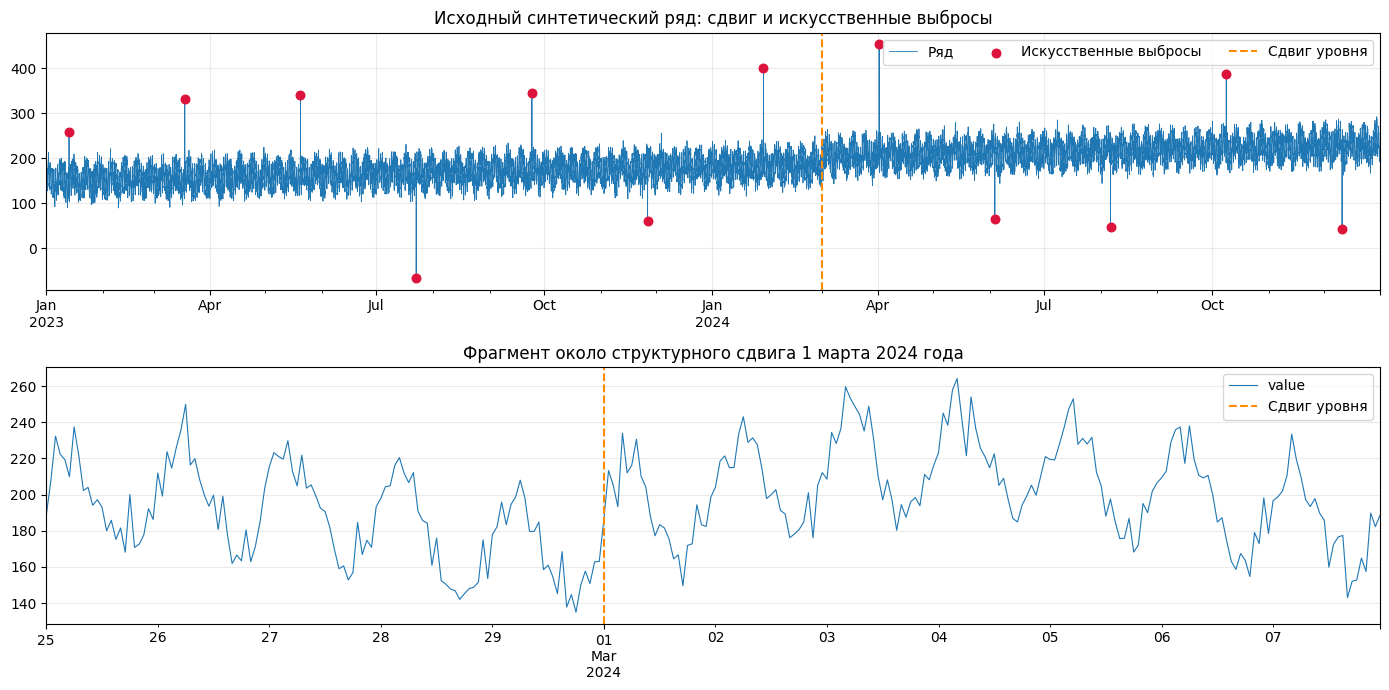

In [3]:
fig, axes = plt.subplots(2, 1, figsize=(14, 7))
series.plot(ax=axes[0], linewidth=0.6, label="Ряд")
axes[0].scatter(
    series.index[outlier_indices], series.iloc[outlier_indices],
    color="crimson", s=38, marker="o", label="Искусственные выбросы", zorder=3
)
axes[0].axvline(SHIFT_START, color="darkorange", linestyle="--", label="Сдвиг уровня")
axes[0].set_title("Исходный синтетический ряд: сдвиг и искусственные выбросы")
axes[0].legend(ncol=3)
series.loc["2024-02-25":"2024-03-07"].plot(ax=axes[1], linewidth=0.8)
axes[1].axvline(SHIFT_START, color="darkorange", linestyle="--", label="Сдвиг уровня")
axes[1].set_title("Фрагмент около структурного сдвига 1 марта 2024 года")
axes[1].legend()
for ax in axes:
    ax.grid(alpha=0.25)
plt.tight_layout()
save_figure(fig, "01_original_series_shift_outliers.png")
plt.show()

## 3. ACF и PACF исходного ряда

ACF показывает общую линейную зависимость с прошлыми значениями. PACF оценивает связь с конкретным лагом после учёта промежуточных лагов. Медленное затухание ACF может указывать на тренд или единичный корень, пики около 24 и 168 соответствуют заданным сезонным периодам. Отдельная CCF не строится, поскольку в наборе данных только один временной ряд.

График сохранён: c:\Users\studio\Desktop\TS_LABS\TS_3\results_lecture3_stationarity\02_original_acf_pacf.png


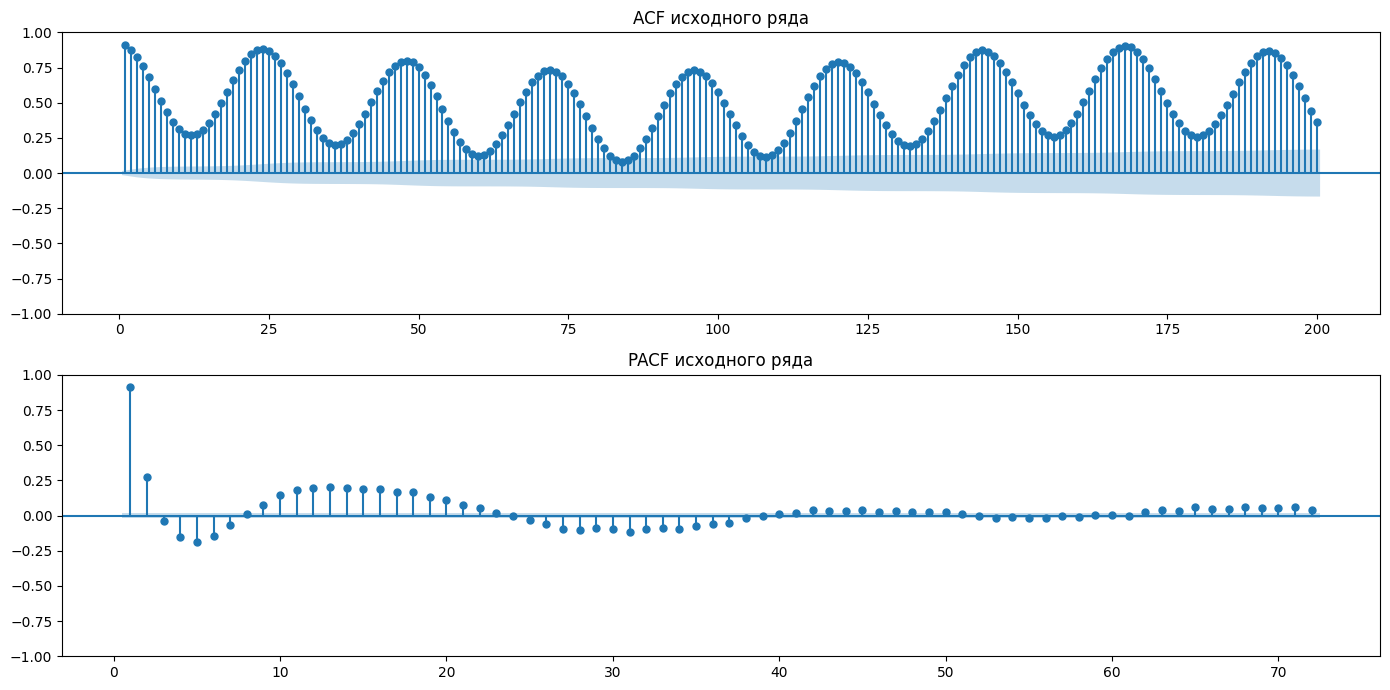

In [4]:
fig, axes = plt.subplots(2, 1, figsize=(14, 7))
plot_acf(series, lags=200, ax=axes[0], alpha=0.05, zero=False)
axes[0].set_title("ACF исходного ряда")
plot_pacf(series, lags=72, ax=axes[1], method="ywm", alpha=0.05, zero=False)
axes[1].set_title("PACF исходного ряда")
plt.tight_layout()
save_figure(fig, "02_original_acf_pacf.png")
plt.show()

## 4. Функция тестирования стационарности

ADF, PP и DF-GLS имеют нулевую гипотезу о наличии единичного корня. Малое p-value говорит против этой гипотезы. У KPSS нулевая гипотеза обратная — стационарность, поэтому малое p-value свидетельствует против стационарности.

Детерминированная часть задаётся отдельно для каждого ряда. Для исходного уровня используется `trend="ct"` (константа и линейный тренд), поскольку линейный тренд заложен в генератор. Для первых и сезонных разностей используется `trend="c"`. Параметр `trend` передаётся всем четырём тестам.

In [5]:
def run_stationarity_tests(x, label, trend="c"):
    """Рассчитывает ADF, PP, KPSS и DF-GLS с заданной детерминированной частью."""
    if not ARCH_AVAILABLE:
        raise ImportError(
            "Для расчёта ADF, PP, KPSS и DF-GLS установите пакет arch: %pip install arch"
        )
    if trend not in {"c", "ct"}:
        raise ValueError("Для этой лабораторной trend должен быть 'c' или 'ct'.")

    x = pd.Series(x).replace([np.inf, -np.inf], np.nan).dropna().astype(float)
    if x.empty:
        raise ValueError(f"Ряд «{label}» не содержит конечных наблюдений.")

    tests = [
        ("ADF", lambda z: ADF(z, trend=trend, method="aic")),
        ("PP", lambda z: PhillipsPerron(z, trend=trend)),
        ("KPSS", lambda z: KPSS(z, trend=trend)),
        ("DF-GLS", lambda z: DFGLS(z, trend=trend, method="aic")),
    ]

    rows = []
    for name, constructor in tests:
        try:
            with warnings.catch_warnings():
                warnings.simplefilter("ignore", DeprecationWarning)
                result = constructor(x)
            rows.append({
                "Ряд": label,
                "Тест": name,
                "Спецификация trend": trend,
                "Статистика": float(result.stat),
                "p-value": float(result.pvalue),
                "Лаги / bandwidth": getattr(result, "lags", np.nan),
                "Реализация": "arch.unitroot"
            })
        except Exception as exc:
            raise RuntimeError(f"Ошибка при расчёте {name} для ряда «{label}»: {exc}") from exc

    order = {"ADF": 0, "PP": 1, "KPSS": 2, "DF-GLS": 3}
    result = pd.DataFrame(rows)
    result["_order"] = result["Тест"].map(order)
    result = result.sort_values("_order").drop(columns="_order").reset_index(drop=True)

    expected = {"ADF", "PP", "KPSS", "DF-GLS"}
    if set(result["Тест"]) != expected or result["p-value"].isna().any():
        raise RuntimeError(f"Не все четыре теста рассчитаны для ряда «{label}». В таблице: {result['Тест'].tolist()}")
    return result

# Уровень проверяется с константой и линейным трендом.
tests_level = run_stationarity_tests(series, "Исходный ряд", trend="ct")
display_full_table(format_test_table(tests_level))

# Проверка устойчивости к 12 искусственно добавленным выбросам.
# Сдвиг уровня 01.03.2024 при этом остаётся в ряду.
tests_level_clean = run_stationarity_tests(
    series_without_outliers, "Исходный ряд без искусственных выбросов", trend="ct"
)
print("Проверка чувствительности к 12 искусственным выбросам:")
display_full_table(format_test_table(tests_level_clean))

outlier_robustness = pd.concat([tests_level, tests_level_clean], ignore_index=True)

,Ряд,Тест,Спецификация trend,Статистика,p-value,Лаги / bandwidth,Реализация
0,Исходный ряд,ADF,ct,"-27,724165","< 0,000001",40,arch.unitroot
1,Исходный ряд,PP,ct,"-37,993140","< 0,000001",44,arch.unitroot
2,Исходный ряд,KPSS,ct,"0,634125","0,0001",53,arch.unitroot
3,Исходный ряд,DF-GLS,ct,"-17,017016","< 0,000001",40,arch.unitroot


Проверка чувствительности к 12 искусственным выбросам:


,Ряд,Тест,Спецификация trend,Статистика,p-value,Лаги / bandwidth,Реализация
0,Исходный ряд без искусственных выбросов,ADF,ct,"-29,470138","< 0,000001",40,arch.unitroot
1,Исходный ряд без искусственных выбросов,PP,ct,"-32,765199","< 0,000001",44,arch.unitroot
2,Исходный ряд без искусственных выбросов,KPSS,ct,"0,634880","0,0001",53,arch.unitroot
3,Исходный ряд без искусственных выбросов,DF-GLS,ct,"-17,680554","< 0,000001",40,arch.unitroot


## 5. Первые разности

Первая разность $\Delta y_t = y_t - y_{t-1}$ часто устраняет стохастический тренд. После преобразования повторяются визуальная диагностика, ACF, PACF и все четыре теста. Для разности используется спецификация с константой (`trend="c"`).

График сохранён: c:\Users\studio\Desktop\TS_LABS\TS_3\results_lecture3_stationarity\03_first_difference_acf_pacf.png


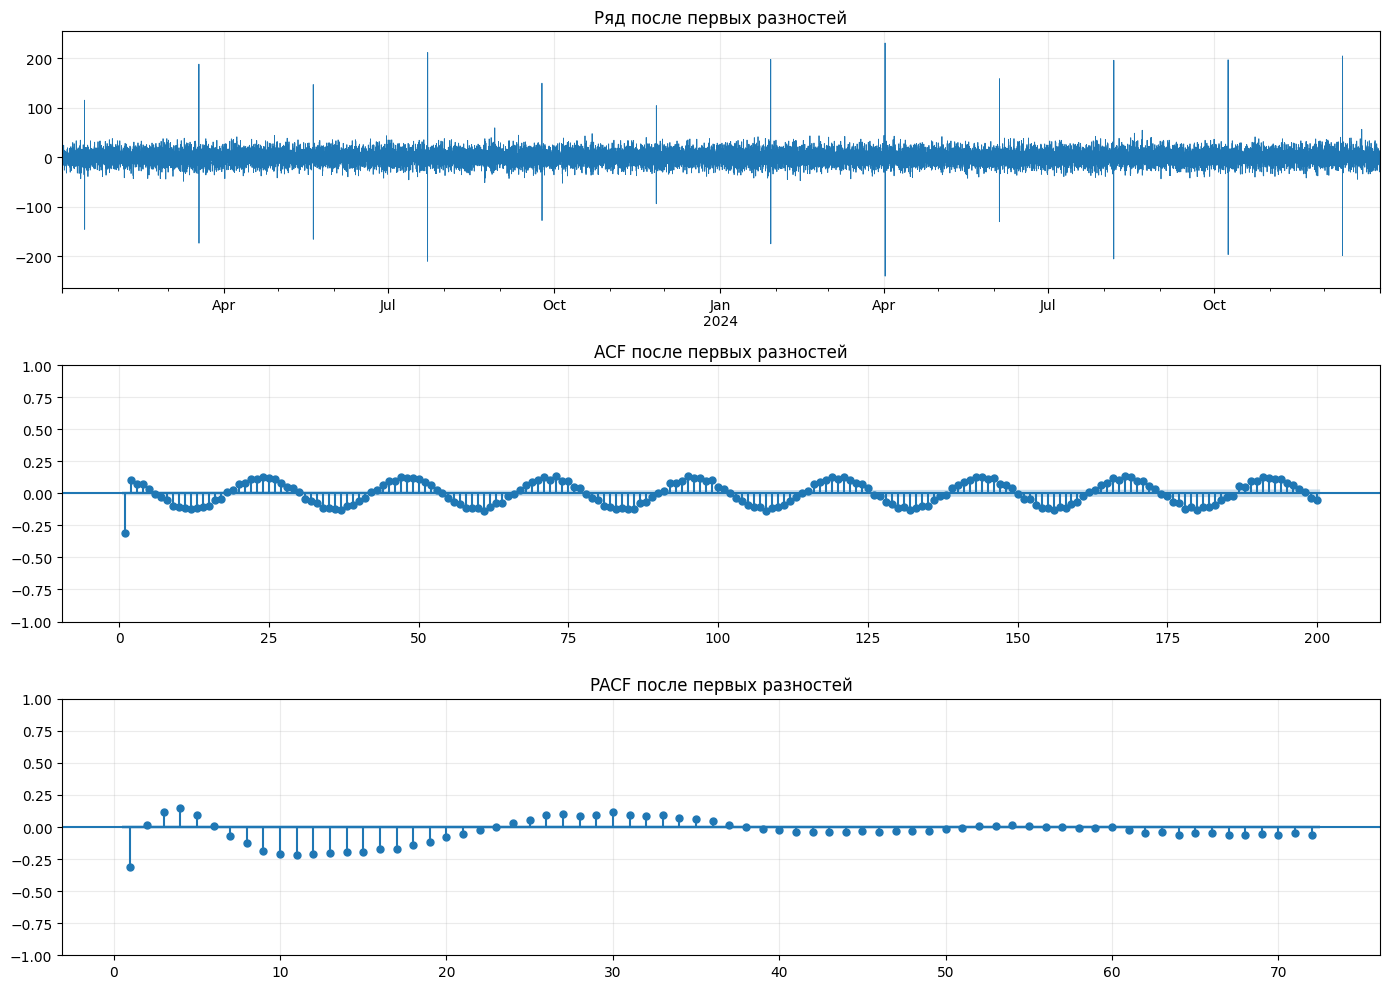

,Ряд,Тест,Спецификация trend,Статистика,p-value,Лаги / bandwidth,Реализация
0,Первая разность,ADF,c,"-16,081087","5,37748e-29",44,arch.unitroot
1,Первая разность,PP,c,"-366,289903","< 0,000001",44,arch.unitroot
2,Первая разность,KPSS,c,"0,000258","0,999941",7,arch.unitroot
3,Первая разность,DF-GLS,c,"-1,461269","0,139398",44,arch.unitroot


In [6]:
diff1 = series.diff().dropna()
fig, axes = plt.subplots(3, 1, figsize=(14, 10))
diff1.plot(ax=axes[0], linewidth=0.6)
axes[0].set_title("Ряд после первых разностей")
plot_acf(diff1, lags=200, ax=axes[1], alpha=0.05, zero=False)
axes[1].set_title("ACF после первых разностей")
plot_pacf(diff1, lags=72, ax=axes[2], method="ywm", alpha=0.05, zero=False)
axes[2].set_title("PACF после первых разностей")
for ax in axes:
    ax.grid(alpha=0.25)
plt.tight_layout()
save_figure(fig, "03_first_difference_acf_pacf.png")
plt.show()
tests_diff1 = run_stationarity_tests(diff1, "Первая разность", trend="c")
display_full_table(format_test_table(tests_diff1))

## 6. Сезонное дифференцирование

Сезонная разность $\Delta_s y_t = y_t-y_{t-s}$ устраняет повторяющуюся структуру с периодом $s$. Здесь проверяется недельный период 168 часов после первых разностей. ACF и PACF сравниваются с результатами до сезонного преобразования. Особое внимание уделяется искусственной отрицательной автокорреляции, которая может указывать на избыточное дифференцирование.

График сохранён: c:\Users\studio\Desktop\TS_LABS\TS_3\results_lecture3_stationarity\04_first_and_seasonal_difference_acf_pacf.png


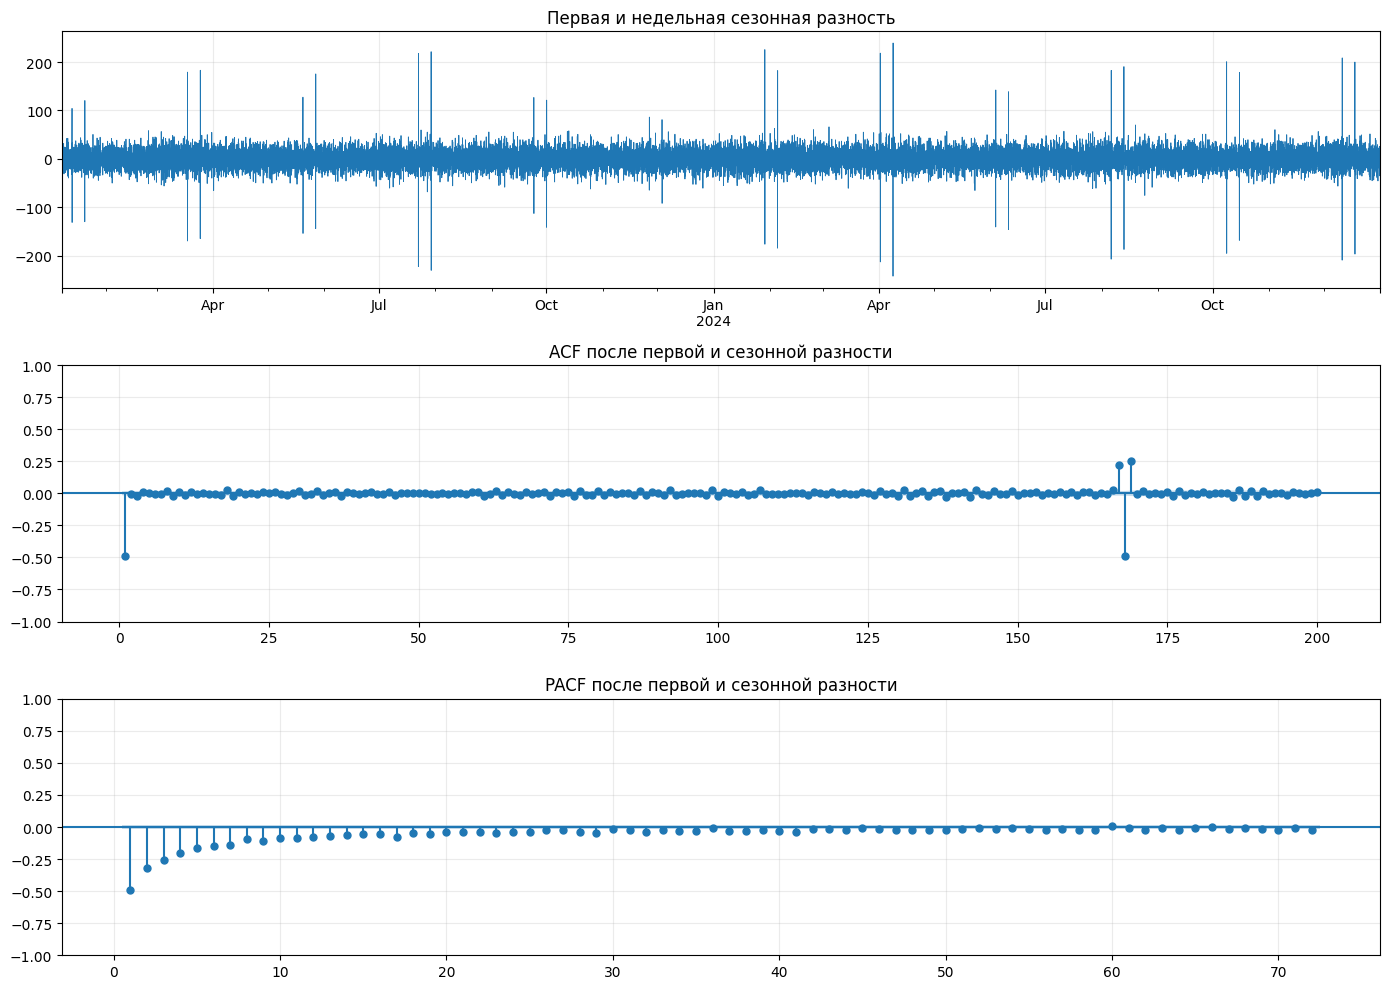

,Ряд,Тест,Спецификация trend,Статистика,p-value,Лаги / bandwidth,Реализация
0,Первая + сезонная разность 168,ADF,c,"-33,669258","< 0,000001",44,arch.unitroot
1,Первая + сезонная разность 168,PP,c,"-871,017674","< 0,000001",44,arch.unitroot
2,Первая + сезонная разность 168,KPSS,c,"0,007732","0,998235",259,arch.unitroot
3,Первая + сезонная разность 168,DF-GLS,c,"-0,418515","0,533752",44,arch.unitroot


In [7]:
SEASONAL_PERIOD = WEEKLY_PERIOD
diff1_seasonal = diff1.diff(SEASONAL_PERIOD).dropna()
fig, axes = plt.subplots(3, 1, figsize=(14, 10))
diff1_seasonal.plot(ax=axes[0], linewidth=0.6)
axes[0].set_title("Первая и недельная сезонная разность")
plot_acf(diff1_seasonal, lags=200, ax=axes[1], alpha=0.05, zero=False)
axes[1].set_title("ACF после первой и сезонной разности")
plot_pacf(diff1_seasonal, lags=72, ax=axes[2], method="ywm", alpha=0.05, zero=False)
axes[2].set_title("PACF после первой и сезонной разности")
for ax in axes:
    ax.grid(alpha=0.25)
plt.tight_layout()
save_figure(fig, "04_first_and_seasonal_difference_acf_pacf.png")
plt.show()
tests_diff1_seasonal = run_stationarity_tests(
    diff1_seasonal, "Первая + сезонная разность 168", trend="c"
)
display_full_table(format_test_table(tests_diff1_seasonal))

## 7. Сводная таблица и интерпретация

Для ADF, PP и DF-GLS малая p-value означает отклонение нулевой гипотезы о единичном корне. Для KPSS малая p-value означает отклонение нулевой гипотезы о стационарности. Поэтому результаты рассматриваются совместно.

In [8]:
tests_all = pd.concat([tests_level, tests_diff1, tests_diff1_seasonal], ignore_index=True)
print("p-value тестов (уровень значимости 0,05):")
row_order = ["ADF", "PP", "KPSS", "DF-GLS"]
column_order = ["Исходный ряд", "Первая разность", "Первая + сезонная разность 168"]
pvalue_pivot = tests_all.pivot(index="Тест", columns="Ряд", values="p-value")
pvalue_pivot = pvalue_pivot.reindex(index=row_order, columns=column_order)
pvalue_pivot = pvalue_pivot.apply(lambda column: column.map(format_pvalue))
display_full_table(pvalue_pivot)

def interpret_tests(table, alpha=0.05):
    """Формирует осторожную совместную интерпретацию четырёх тестов."""
    rows = []
    for label, part in table.groupby("Ряд", sort=False):
        p = part.set_index("Тест")["p-value"]
        unit_root_names = [name for name in ["ADF", "PP", "DF-GLS"] if name in p.index and pd.notna(p[name])]
        rejected = [name for name in unit_root_names if float(p[name]) < alpha]
        unit_root_votes = len(rejected)
        unit_root_total = len(unit_root_names)
        kpss_available = "KPSS" in p.index and pd.notna(p.get("KPSS", np.nan))
        kpss_not_reject = bool(kpss_available and float(p["KPSS"]) >= alpha)

        if not kpss_available or unit_root_total != 3:
            verdict = "Недостаточно результатов для совместной интерпретации всех четырёх тестов."
        elif unit_root_votes == 3 and kpss_not_reject:
            verdict = (
                "Все три теста ADF/PP/DF-GLS отвергают гипотезу о единичном корне, "
                "а KPSS не отвергает гипотезу о стационарности. Результаты согласованно "
                "поддерживают стационарность в рамках выбранной спецификации."
            )
        elif unit_root_votes in (1, 2) and kpss_not_reject:
            verdict = (
                f"{unit_root_votes} из {unit_root_total} тестов ADF/PP/DF-GLS отвергают "
                "гипотезу о единичном корне, KPSS не отвергает гипотезу о стационарности. "
                "Результаты частично поддерживают стационарность, но не полностью согласованы; "
                "в частности, следует учитывать результат теста, не отвергшего единичный корень."
            )
        elif unit_root_votes >= 2 and not kpss_not_reject:
            verdict = (
                f"{unit_root_votes} из {unit_root_total} тестов ADF/PP/DF-GLS отвергают "
                "гипотезу о единичном корне, но KPSS отвергает гипотезу о стационарности. "
                "Результаты противоречивы; возможны влияние сезонности, структурного сдвига "
                "или неверно заданной детерминированной части."
            )
        elif unit_root_votes <= 1 and kpss_not_reject:
            verdict = (
                f"Только {unit_root_votes} из {unit_root_total} тестов ADF/PP/DF-GLS отвергают "
                "гипотезу о единичном корне, тогда как KPSS не отвергает стационарность. "
                "Результаты не дают согласованного вывода."
            )
        else:
            verdict = (
                f"Только {unit_root_votes} из {unit_root_total} тестов ADF/PP/DF-GLS отвергают "
                "гипотезу о единичном корне, а KPSS отвергает стационарность. Это указывает "
                "на нестационарность, но остаётся необходимым учитывать возможный структурный сдвиг."
            )

        def test_status(name, reject_text, not_reject_text):
            value = p.get(name, np.nan)
            if pd.isna(value):
                return "нет результата"
            return reject_text if float(value) < alpha else not_reject_text

        rows.append({
            "Ряд": label,
            "ADF": test_status("ADF", "отвергает H0 о единичном корне", "не отвергает H0 о единичном корне"),
            "PP": test_status("PP", "отвергает H0 о единичном корне", "не отвергает H0 о единичном корне"),
            "KPSS": (
                "нет результата" if not kpss_available else
                ("не отвергает H0 о стационарности" if kpss_not_reject else "отвергает H0 о стационарности")
            ),
            "DF-GLS": test_status("DF-GLS", "отвергает H0 о единичном корне", "не отвергает H0 о единичном корне"),
            "Число тестов, отвергающих H0 о единичном корне": f"{unit_root_votes} из {unit_root_total}",
            "Интерпретация": verdict
        })
    return pd.DataFrame(rows)

interpretation = interpret_tests(tests_all)
display_full_table(interpretation)

# Контрольные значения ACF на лагах 1, 24, 168 и 336.
acf_rows = []
for label, x in [
    ("Исходный ряд", series),
    ("Первая разность", diff1),
    ("Первая + сезонная разность 168", diff1_seasonal),
]:
    values = acf(x, nlags=336, fft=True)
    for lag in [1, 24, 168, 336]:
        acf_rows.append({"Ряд": label, "Лаг": lag, "ACF": float(values[lag])})
acf_summary = pd.DataFrame(acf_rows)
print("Контрольные значения ACF:")
display_full_table(acf_summary.pivot(index="Лаг", columns="Ряд", values="ACF").reindex(columns=column_order).round(4))

# Ljung–Box оценивает наличие остаточной автокорреляции, но сам по себе не проверяет стационарность.
ljung_box_rows = []
for label, x in [("Первая разность", diff1), ("Первая + сезонная разность 168", diff1_seasonal)]:
    lb = acorr_ljungbox(x, lags=[24, 48, 168], return_df=True)
    for lag, row in lb.iterrows():
        ljung_box_rows.append({
            "Ряд": label,
            "Лаг": int(lag),
            "Статистика Ljung–Box": float(row["lb_stat"]),
            "p-value": float(row["lb_pvalue"])
        })
ljung_box_summary = pd.DataFrame(ljung_box_rows)
print("Тест Ljung–Box для преобразованных рядов:")
display_full_table(format_test_table(ljung_box_summary.rename(columns={"Статистика Ljung–Box": "Статистика"})))
print("Малое p-value Ljung–Box указывает на остаточную автокорреляцию на рассматриваемом диапазоне лагов, это не является тестом единичного корня.")

p-value тестов (уровень значимости 0,05):


Ряд,Исходный ряд,Первая разность,Первая + сезонная разность 168
Тест,,,
ADF,"< 0,000001","5,37748e-29","< 0,000001"
PP,"< 0,000001","< 0,000001","< 0,000001"
KPSS,"0,0001","0,999941","0,998235"
DF-GLS,"< 0,000001","0,139398","0,533752"


,Ряд,ADF,PP,KPSS,DF-GLS,"Число тестов, отвергающих H0 о единичном корне",Интерпретация
0,Исходный ряд,отвергает H0 о единичном корне,отвергает H0 о единичном корне,отвергает H0 о стационарности,отвергает H0 о единичном корне,3 из 3,"3 из 3 тестов ADF/PP/DF-GLS отвергают гипотезу о единичном корне, но KPSS отвергает гипотезу о стационарности. Результаты противоречивы; возможны влияние сезонности, структурного сдвига или неверно заданной детерминированной части."
1,Первая разность,отвергает H0 о единичном корне,отвергает H0 о единичном корне,не отвергает H0 о стационарности,не отвергает H0 о единичном корне,2 из 3,"2 из 3 тестов ADF/PP/DF-GLS отвергают гипотезу о единичном корне, KPSS не отвергает гипотезу о стационарности. Результаты частично поддерживают стационарность, но не полностью согласованы; в частности, следует учитывать результат теста, не отвергшего единичный корень."
2,Первая + сезонная разность 168,отвергает H0 о единичном корне,отвергает H0 о единичном корне,не отвергает H0 о стационарности,не отвергает H0 о единичном корне,2 из 3,"2 из 3 тестов ADF/PP/DF-GLS отвергают гипотезу о единичном корне, KPSS не отвергает гипотезу о стационарности. Результаты частично поддерживают стационарность, но не полностью согласованы; в частности, следует учитывать результат теста, не отвергшего единичный корень."


Контрольные значения ACF:


Ряд,Исходный ряд,Первая разность,Первая + сезонная разность 168
Лаг,,,
1,0.911600,-0.309300,-0.487800
24,0.884400,0.129400,0.007800
168,0.904800,0.132500,-0.492800
336,0.888200,0.123500,-0.001800


Тест Ljung–Box для преобразованных рядов:


,Ряд,Лаг,Статистика,p-value
0,Первая разность,24,"4667,585182","< 0,000001"
1,Первая разность,48,"7905,915343","< 0,000001"
2,Первая разность,168,"24240,900661","< 0,000001"
3,Первая + сезонная разность 168,24,"4201,285604","< 0,000001"
4,Первая + сезонная разность 168,48,"4245,675234","< 0,000001"
5,Первая + сезонная разность 168,168,"9662,855296","< 0,000001"


Малое p-value Ljung–Box указывает на остаточную автокорреляцию на рассматриваемом диапазоне лагов, это не является тестом единичного корня.


## 8. Автоматический подбор порядков d и D

`ndiffs()` рекомендует порядок обычного дифференцирования `d`, `nsdiffs()` — сезонного `D`. Для полноты сезонные тесты запускаются отдельно для обоих периодов, присутствующих в генераторе: 24 и 168 часов. Автоматические рекомендации являются ориентиром и не заменяют визуальный анализ.

In [9]:
auto_rows = []

for test_name in ["adf", "kpss", "pp"]:
    algorithm = f"ndiffs, test={test_name}"
    try:
        order = int(ndiffs(series.to_numpy(), test=test_name, max_d=2))
        auto_rows.append({
            "Алгоритм": algorithm, "m": "—", "Порядок": order,
            "Статус": "успешно", "Комментарий": "порядок обычного дифференцирования d"
        })
    except Exception as exc:
        auto_rows.append({
            "Алгоритм": algorithm, "m": "—", "Порядок": np.nan,
            "Статус": "ошибка", "Комментарий": str(exc)
        })

for period in [DAILY_PERIOD, WEEKLY_PERIOD]:
    for test_name in ["ch", "ocsb"]:
        algorithm = f"nsdiffs, test={test_name}"
        try:
            order = int(nsdiffs(series.to_numpy(), m=period, test=test_name, max_D=1))
            auto_rows.append({
                "Алгоритм": algorithm, "m": period, "Порядок": order,
                "Статус": "успешно", "Комментарий": "порядок сезонного дифференцирования D"
            })
        except Exception as exc:
            auto_rows.append({
                "Алгоритм": algorithm, "m": period, "Порядок": np.nan,
                "Статус": "ошибка", "Комментарий": str(exc)
            })

auto_orders = pd.DataFrame(auto_rows)
display_full_table(auto_orders)

auto_map = {(row["Алгоритм"], row["m"]): row["Порядок"] for _, row in auto_orders.iterrows()}
print("Автоматический выбор:")
for test_name in ["adf", "kpss", "pp"]:
    print(f"  d ({test_name}) = {auto_map.get((f'ndiffs, test={test_name}', '—'))}")
for period in [DAILY_PERIOD, WEEKLY_PERIOD]:
    for test_name in ["ch", "ocsb"]:
        print(f"  D ({test_name}, m={period}) = {auto_map.get((f'nsdiffs, test={test_name}', period))}")

,Алгоритм,m,Порядок,Статус,Комментарий
0,"ndiffs, test=adf",—,0,успешно,порядок обычного дифференцирования d
1,"ndiffs, test=kpss",—,1,успешно,порядок обычного дифференцирования d
2,"ndiffs, test=pp",—,0,успешно,порядок обычного дифференцирования d
3,"nsdiffs, test=ch",24,0,успешно,порядок сезонного дифференцирования D
4,"nsdiffs, test=ocsb",24,0,успешно,порядок сезонного дифференцирования D
5,"nsdiffs, test=ch",168,0,успешно,порядок сезонного дифференцирования D
6,"nsdiffs, test=ocsb",168,0,успешно,порядок сезонного дифференцирования D


Автоматический выбор:
  d (adf) = 0
  d (kpss) = 1
  d (pp) = 0
  D (ch, m=24) = 0
  D (ocsb, m=24) = 0
  D (ch, m=168) = 0
  D (ocsb, m=168) = 0


## 9. Проверка необходимости логарифмирования

Логарифмирование или Box–Cox применяются, если дисперсия заметно зависит от уровня ряда. В работе проверяется скользящее стандартное отклонение с окном 7 дней. Обычный логарифм и стандартное преобразование Box–Cox требуют положительных значений, произвольный сдвиг ряда не вводится.

График сохранён: c:\Users\studio\Desktop\TS_LABS\TS_3\results_lecture3_stationarity\05_rolling_mean_and_std.png


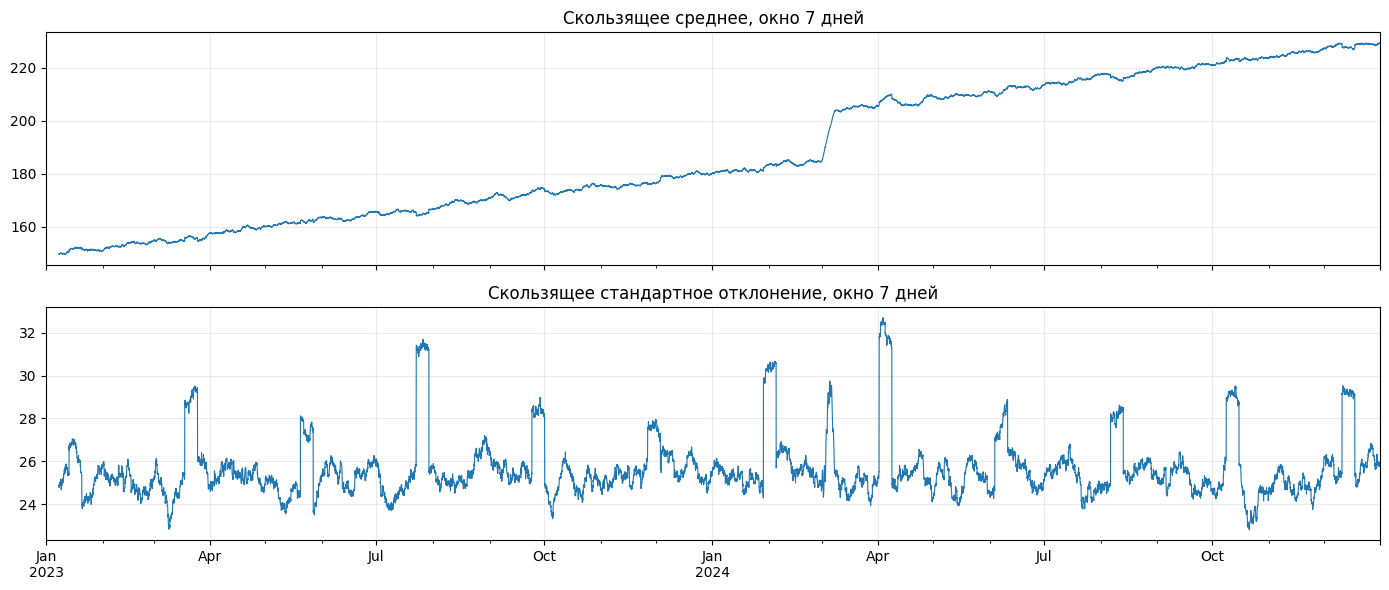

Логарифмирование и стандартный Box–Cox не применяются: в ряду есть неположительные значения.
Минимум ряда: -66.2283


In [10]:
rolling_mean = series.rolling(24 * 7).mean()
rolling_std = series.rolling(24 * 7).std()
fig, axes = plt.subplots(2, 1, figsize=(14, 6), sharex=True)
rolling_mean.plot(ax=axes[0], linewidth=0.8)
axes[0].set_title("Скользящее среднее, окно 7 дней")
rolling_std.plot(ax=axes[1], linewidth=0.8)
axes[1].set_title("Скользящее стандартное отклонение, окно 7 дней")
for ax in axes:
    ax.grid(alpha=0.25)
plt.tight_layout()
save_figure(fig, "05_rolling_mean_and_std.png")
plt.show()

if (series > 0).all():
    log_series = np.log(series)
    fig, axes = plt.subplots(2, 1, figsize=(14, 6))
    series.plot(ax=axes[0], linewidth=0.6)
    axes[0].set_title("Исходный ряд")
    log_series.plot(ax=axes[1], linewidth=0.6)
    axes[1].set_title("Логарифм исходного ряда")
    plt.tight_layout()
    save_figure(fig, "06_log_transform.png")
    plt.show()
else:
    print("Логарифмирование и стандартный Box–Cox не применяются: в ряду есть неположительные значения.")
    print("Минимум ряда:", round(float(series.min()), 4))

## 10. Краткий отчёт по результатам

Ниже приводятся фактические p-value всех четырёх тестов, их совместная интерпретация, проверка чувствительности к выбросам и диагностика остаточной автокорреляции. Для исходного уровня используется спецификация `trend="ct"`, для преобразованных рядов — `trend="c"`.

In [11]:
def pvalue_text(table, label):
    part = table[table["Ряд"] == label].set_index("Тест")["p-value"]
    return "; ".join(
        f"{name}: {format_pvalue(part.get(name, np.nan))}"
        for name in ["ADF", "PP", "KPSS", "DF-GLS"]
    )

for label in ["Исходный ряд", "Первая разность", "Первая + сезонная разность 168"]:
    print(label + " — " + pvalue_text(tests_all, label))

print("\nПроверка устойчивости исходного уровня к исключению искусственных выбросов:")
robustness_pivot = outlier_robustness.pivot(index="Тест", columns="Ряд", values="p-value").reindex(index=["ADF", "PP", "KPSS", "DF-GLS"])
display_full_table(robustness_pivot.apply(lambda col: col.map(format_pvalue)))

print("\nИнтерпретация тестов:")
display_full_table(interpretation[["Ряд", "Интерпретация"]])

print("\nАвтоматический подбор порядков:")
display_full_table(auto_orders)

print("\nДиагностика Ljung–Box:")
display_full_table(format_test_table(ljung_box_summary.rename(columns={"Статистика Ljung–Box": "Статистика"})))

Исходный ряд — ADF: < 0,000001; PP: < 0,000001; KPSS: 0,0001; DF-GLS: < 0,000001
Первая разность — ADF: 5,37748e-29; PP: < 0,000001; KPSS: 0,999941; DF-GLS: 0,139398
Первая + сезонная разность 168 — ADF: < 0,000001; PP: < 0,000001; KPSS: 0,998235; DF-GLS: 0,533752

Проверка устойчивости исходного уровня к исключению искусственных выбросов:


Ряд,Исходный ряд,Исходный ряд без искусственных выбросов
Тест,,
ADF,"< 0,000001","< 0,000001"
PP,"< 0,000001","< 0,000001"
KPSS,"0,0001","0,0001"
DF-GLS,"< 0,000001","< 0,000001"



Интерпретация тестов:


,Ряд,Интерпретация
0,Исходный ряд,"3 из 3 тестов ADF/PP/DF-GLS отвергают гипотезу о единичном корне, но KPSS отвергает гипотезу о стационарности. Результаты противоречивы; возможны влияние сезонности, структурного сдвига или неверно заданной детерминированной части."
1,Первая разность,"2 из 3 тестов ADF/PP/DF-GLS отвергают гипотезу о единичном корне, KPSS не отвергает гипотезу о стационарности. Результаты частично поддерживают стационарность, но не полностью согласованы; в частности, следует учитывать результат теста, не отвергшего единичный корень."
2,Первая + сезонная разность 168,"2 из 3 тестов ADF/PP/DF-GLS отвергают гипотезу о единичном корне, KPSS не отвергает гипотезу о стационарности. Результаты частично поддерживают стационарность, но не полностью согласованы; в частности, следует учитывать результат теста, не отвергшего единичный корень."



Автоматический подбор порядков:


,Алгоритм,m,Порядок,Статус,Комментарий
0,"ndiffs, test=adf",—,0,успешно,порядок обычного дифференцирования d
1,"ndiffs, test=kpss",—,1,успешно,порядок обычного дифференцирования d
2,"ndiffs, test=pp",—,0,успешно,порядок обычного дифференцирования d
3,"nsdiffs, test=ch",24,0,успешно,порядок сезонного дифференцирования D
4,"nsdiffs, test=ocsb",24,0,успешно,порядок сезонного дифференцирования D
5,"nsdiffs, test=ch",168,0,успешно,порядок сезонного дифференцирования D
6,"nsdiffs, test=ocsb",168,0,успешно,порядок сезонного дифференцирования D



Диагностика Ljung–Box:


,Ряд,Лаг,Статистика,p-value
0,Первая разность,24,"4667,585182","< 0,000001"
1,Первая разность,48,"7905,915343","< 0,000001"
2,Первая разность,168,"24240,900661","< 0,000001"
3,Первая + сезонная разность 168,24,"4201,285604","< 0,000001"
4,Первая + сезонная разность 168,48,"4245,675234","< 0,000001"
5,Первая + сезонная разность 168,168,"9662,855296","< 0,000001"


## 11. Сохранение результатов

Сохраняются ряды, компоненты генератора, даты выбросов, таблицы тестов, интерпретации, ACF, Ljung–Box и все построенные графики.

In [12]:
series.to_frame().to_csv(OUTPUT_DIR / "01_synthetic_series.csv", index_label="timestamp")
series_without_outliers.to_frame().to_csv(OUTPUT_DIR / "02_series_without_artificial_outliers.csv", index_label="timestamp")
diff1.to_frame("diff1").to_csv(OUTPUT_DIR / "03_first_difference.csv", index_label="timestamp")
diff1_seasonal.to_frame("diff1_seasonal_168").to_csv(
    OUTPUT_DIR / "04_first_and_seasonal_difference_168.csv", index_label="timestamp"
)
tests_all.to_csv(OUTPUT_DIR / "05_stationarity_tests.csv", index=False)
outlier_robustness.to_csv(OUTPUT_DIR / "06_outlier_robustness_tests.csv", index=False)
interpretation.to_csv(OUTPUT_DIR / "07_test_interpretation.csv", index=False)
acf_summary.to_csv(OUTPUT_DIR / "08_acf_summary.csv", index=False)
ljung_box_summary.to_csv(OUTPUT_DIR / "09_ljung_box.csv", index=False)
auto_orders.to_csv(OUTPUT_DIR / "10_automatic_differencing_orders.csv", index=False)
outlier_table.to_csv(OUTPUT_DIR / "11_injected_outliers.csv", index=False)
true_components.to_csv(OUTPUT_DIR / "12_true_components.csv", index_label="timestamp")
print("Таблицы и ряды сохранены в:", OUTPUT_DIR.resolve())
print("Графики сохранены в той же папке.")

Таблицы и ряды сохранены в: C:\Users\studio\Desktop\TS_LABS\TS_3\results_lecture3_stationarity
Графики сохранены в той же папке.


## Заключение

В работе построен синтетический почасовой ряд из 17 544 наблюдений с линейным трендом, суточной и недельной сезонностью, структурным сдвигом и 12 выбросами.

Для исходного ряда ADF, PP и DF-GLS отвергают гипотезу о единичном корне, однако KPSS отвергает гипотезу о стационарности. Результаты тестов противоречивы, поэтому однозначно считать исходный ряд стационарным нельзя.

После первых разностей результаты тестов преимущественно подтверждают стационарность: ADF и PP отвергают наличие единичного корня, KPSS не отвергает стационарность. DF-GLS остаётся исключением. Сезонные разности не получили подтверждения от `nsdiffs()` для периодов 24 и 168. Более того, отрицательные значения ACF на лагах 1 и 168 указывают на риск избыточного дифференцирования.

Исключение выбросов не изменило результаты тестов, однако влияние структурного сдвига отдельно не учитывалось. Критерий Ljung–Box выявил сохраняющуюся автокорреляцию, поэтому преобразование ряда само по себе не устраняет необходимость моделирования его динамики.

В качестве рабочего варианта принимается **d = 1, D = 0**. Окончательный выбор между моделями с дифференцированием и без него следует сделать по диагностике остатков и качеству прогноза. Логарифмирование и Box–Cox не применялись из-за наличия неположительных значений в исходном ряде.